,Scenario,H0,H1
0,Delivery time,Mean delivery time is 30 minutes,Mean delivery time is not 30 minutes
1,Website conversion,Conversion rates are equal for A and B,Conversion rates differ for A and B
2,Customer satisfaction,Mean satisfaction score is 4.0,Mean satisfaction score differs from 4.0


ONE-SAMPLE T-TEST: Delivery Time
Sample mean: 29.60 minutes
95% confidence interval: (np.float64(28.696560551329867), np.float64(30.503439448670136))
t-statistic: -0.927
p-value: 0.3657
Decision: Fail to reject H0

TWO-SAMPLE T-TEST: Group A vs Group B
Group A mean: 4.06
Group B mean: 3.76
Mean difference (A - B): 0.30
95% confidence interval for difference: (np.float64(0.11929978951776735), np.float64(0.4807002104822323))
t-statistic: 3.561
p-value: 0.0031
Decision: Reject H0

CUSTOMER SATISFACTION TEST
Sample mean: 4.03
p-value: 0.5457
Decision: Fail to reject H0


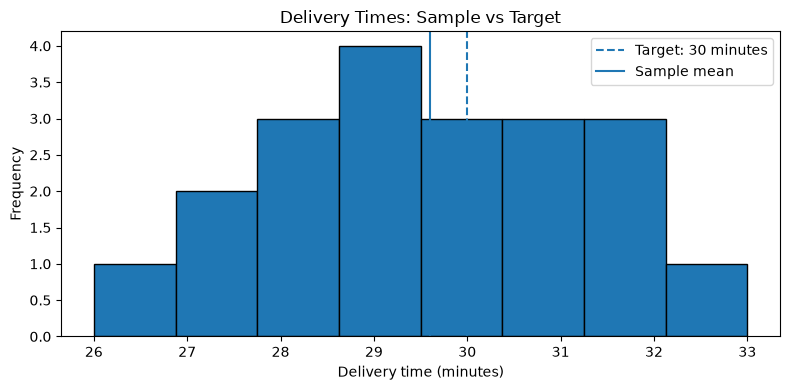


BUSINESS INTERPRETATION
Type I error: Conclude delivery time changed when it has not.
Business impact: An unnecessary operational change.
Type II error: Miss a real change in delivery time.
Business impact: A genuine delivery problem may remain unresolved.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Significance level
alpha = 0.05

# Business scenarios
scenarios = pd.DataFrame([
    {
        "Scenario": "Delivery time",
        "H0": "Mean delivery time is 30 minutes",
        "H1": "Mean delivery time is not 30 minutes"
    },
    {
        "Scenario": "Website conversion",
        "H0": "Conversion rates are equal for A and B",
        "H1": "Conversion rates differ for A and B"
    },
    {
        "Scenario": "Customer satisfaction",
        "H0": "Mean satisfaction score is 4.0",
        "H1": "Mean satisfaction score differs from 4.0"
    }
])

display(scenarios)

# Scenario 1: One-sample t-test
delivery_times = np.array([
    28, 32, 29, 31, 27, 30, 33, 29, 31, 28,
    30, 32, 26, 29, 31, 28, 30, 27, 32, 29
])

target_time = 30

one_sample = stats.ttest_1samp(delivery_times, popmean=target_time)
one_sample_ci = stats.t.interval(
    confidence=0.95,
    df=len(delivery_times) - 1,
    loc=np.mean(delivery_times),
    scale=stats.sem(delivery_times)
)

print("ONE-SAMPLE T-TEST: Delivery Time")
print(f"Sample mean: {np.mean(delivery_times):.2f} minutes")
print(f"95% confidence interval: {one_sample_ci}")
print(f"t-statistic: {one_sample.statistic:.3f}")
print(f"p-value: {one_sample.pvalue:.4f}")
print(
    "Decision:",
    "Reject H0" if one_sample.pvalue < alpha else "Fail to reject H0"
)

# Scenario 2: Two-sample t-test
group_a = np.array([4.2, 4.0, 3.9, 4.3, 4.1, 4.0, 3.8, 4.2])
group_b = np.array([3.7, 3.9, 3.8, 3.6, 4.0, 3.7, 3.9, 3.5])

two_sample = stats.ttest_ind(group_a, group_b, equal_var=False)

mean_difference = np.mean(group_a) - np.mean(group_b)
se_difference = np.sqrt(
    np.var(group_a, ddof=1) / len(group_a)
    + np.var(group_b, ddof=1) / len(group_b)
)

df_welch = (
    (np.var(group_a, ddof=1) / len(group_a)
     + np.var(group_b, ddof=1) / len(group_b)) ** 2
    / (
        (np.var(group_a, ddof=1) / len(group_a)) ** 2 / (len(group_a) - 1)
        + (np.var(group_b, ddof=1) / len(group_b)) ** 2 / (len(group_b) - 1)
    )
)

critical_t = stats.t.ppf(0.975, df_welch)
two_sample_ci = (
    mean_difference - critical_t * se_difference,
    mean_difference + critical_t * se_difference
)

print("\nTWO-SAMPLE T-TEST: Group A vs Group B")
print(f"Group A mean: {np.mean(group_a):.2f}")
print(f"Group B mean: {np.mean(group_b):.2f}")
print(f"Mean difference (A - B): {mean_difference:.2f}")
print(f"95% confidence interval for difference: {two_sample_ci}")
print(f"t-statistic: {two_sample.statistic:.3f}")
print(f"p-value: {two_sample.pvalue:.4f}")
print(
    "Decision:",
    "Reject H0" if two_sample.pvalue < alpha else "Fail to reject H0"
)

# Scenario 3: Customer satisfaction one-sample test
satisfaction = np.array([
    4.1, 3.9, 4.2, 4.0, 3.8, 4.3, 4.1, 3.9,
    4.0, 4.2, 3.7, 4.1, 4.0, 3.9, 4.2
])

satisfaction_test = stats.ttest_1samp(satisfaction, popmean=4.0)

print("\nCUSTOMER SATISFACTION TEST")
print(f"Sample mean: {np.mean(satisfaction):.2f}")
print(f"p-value: {satisfaction_test.pvalue:.4f}")
print(
    "Decision:",
    "Reject H0" if satisfaction_test.pvalue < alpha else "Fail to reject H0"
)

# Visualize delivery-time distribution
plt.figure(figsize=(8, 4))
plt.hist(delivery_times, bins=8, edgecolor="black")
plt.axvline(target_time, linestyle="--", label="Target: 30 minutes")
plt.axvline(np.mean(delivery_times), linestyle="-", label="Sample mean")
plt.title("Delivery Times: Sample vs Target")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

# Type I and Type II errors
print("\nBUSINESS INTERPRETATION")
print("Type I error: Conclude delivery time changed when it has not.")
print("Business impact: An unnecessary operational change.")
print("Type II error: Miss a real change in delivery time.")
print("Business impact: A genuine delivery problem may remain unresolved.")